# 14 - NMR Petrophysics

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_b_advanced/14_nmr_petrophysics.ipynb)

**Part B - Petrophys Curriculum**

Nuclear Magnetic Resonance (NMR) logging measures the relaxation of hydrogen
protons in the pore fluid. NMR porosity does not require the matrix-density or matrix-slowness endpoints
used by density and sonic porosity. Its interpretation still depends on fluid
hydrogen index, polarization time, echo spacing and borehole conditions.
T2 distributions can constrain pore sizes and bound/free-fluid volumes under
suitable fluid, wettability and surface-relaxation assumptions; permeability
comes from an empirical transform, not a direct measurement.

This lesson works the `petrophys.interpretation.nmr` toolkit on a **real CMR log**: the
Schlumberger CMR summary deliverable from **Daydream 1** (QGC, ATP 645, Bowen
Basin, Queensland) - the same publicly released well whose FMI drives
lesson 16. Two depth sections ship with the package; we use the deep one
(3755-4145 m) and leave the shallow one for the exercises.

The deliverable is a **summary** export: total and free-fluid porosity, the T2
cutoff and the vendor permeabilities. It does **not** contain the per-depth T2
distribution (the T2 bins), so this lesson works with the summary curves and
shows how the library refuses bin-based products rather than inventing them.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

By the end of this lesson you will be able to:

- Load a real CMR summary deliverable into `NMRData` with `from_las`
  (mnemonic aliases, automatic v/v-to-pu conversion, `MBVI` derived as
  `MPHI - MFFI`).
- Read the porosity partition (bound vs free fluid) and **Swirr** from real
  curves, at the T2 cutoff recorded in the file itself.
- Compute **Timur-Coates permeability** from the summary curves and validate
  it against the vendor's own `KTIM`, recovering the vendor's constant with
  `calibrate_coates`.
- Know which products need **T2 bins** (T2 distribution, T2lm, SDR
  permeability, pore size) and how `NMRData` refuses rather than guesses when
  they are absent.

## Why this matters (the physics)

After a polarizing pulse, hydrogen protons in the pore fluid relax back to
equilibrium with a **transverse relaxation time $T_2$**. In a water-wet rock the
dominant mechanism is *surface relaxation*, and to first order

$$\frac{1}{T_2} \approx \rho_2\,\frac{S}{V},$$

where $\rho_2$ is the surface relaxivity and $S/V$ is the pore surface-to-volume
ratio. Small pores have a **large** $S/V$ and relax **fast** (short $T_2$); large
pores relax slowly (long $T_2$). So the measured **T2 distribution is a proxy for
the pore-size distribution**:

- **Short $T_2$** -> tiny/clay-bound and capillary-bound water -> **irreducible** (BVI).
- **Long $T_2$** -> large pores holding **movable** (free) fluid (FFI).

A processing **T2 cutoff** partitions these volumes under the chosen model. The total area under the T2
distribution is the **NMR porosity (MPHI)** after the acquisition and fluid-response corrections.
A bound/free-fluid split is an interpretation: short-T2 hydrocarbons and
wettability can invalidate a simple identification of BVI with water.
The 33-ms and 92-ms defaults are starting parameters, not universal contacts
between pore or fluid types. A summary export such as ours keeps the results of
that split (total porosity, free fluid, the cutoff used) but not the
distribution itself.

### Prerequisites
This lesson assumes you have worked through the Part A porosity (04) and
permeability (08) lessons. Basic familiarity with porosity units (fractions
vs porosity units, "pu" = percent) is helpful.

In [2]:
import pandas as pd
import petrophys as pp
from petrophys.interpretation.nmr import NMRData

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)

## 1. Load the real CMR deliverable

The bundled `daydream1_cmr.las` is the service company's standard CMR summary
export: total porosity `TCMR`, free fluid `CMFF`, 3-ms porosity `CMRP_3MS`,
the vendor's SDR and Timur permeabilities `KSDR` / `KTIM`, the `T2CUTOFF`
used in the delivered processing, plus GR and calipers for QC.

`NMRData.from_las` does the housekeeping:

- resolves CMR mnemonics onto the MRIL-style names the container uses
  (`TCMR -> MPHI`, `CMFF -> MFFI`),
- converts fractional (v/v) porosities to **pu**,
- derives `MBVI = MPHI - MFFI` when no bound-fluid curve is present,
- reads the T2 cutoff from the `T2CUTOFF` curve, unless you pass `t2_cutoff=`
  (which then holds at every depth),
- stores the vendor permeabilities and every remaining curve
  (`stored_permeability`, `extra_curves`).

One quirk of the file: it is written deepest-first (decreasing depth). That is
a valid, monotonic depth index, so it loads without a warning, and per-sample
NMR arithmetic is unaffected. Just remember that the first row is the deepest
sample (the export table in section 5 shows it).

In [3]:
nmr = NMRData.from_las(pp.sample("daydream1_cmr"))
nmr

NMRData(samples=15606, depth=3755.0-4145.1, MFFI, MBVI, stored perm, schlumberger_cmr, cutoff=33.0ms)

15,606 samples from 3755.0 to 4145.1 m, free and bound fluid (`MFFI`, `MBVI`),
the vendor permeabilities, and the 33 ms cutoff read from the `T2CUTOFF` curve.
`nmr.stored_permeability` holds `KSDR` and `KTIM`, `nmr.extra_curves` the other
curves of the file.

## 2. Summary curves vs T2 bins

This deliverable carries **summary curves only** - the per-depth T2 bin
amplitudes (the full T2 distribution) were never exported to LAS
(`nmr.has_bins` and `nmr.has_t2lm` are False). That rules out the bin-based
products:

- the **T2 distribution** itself and its **log-mean T2lm**,
- **SDR permeability** ($k = C\,\phi^4\,T2_{lm}^2$), which needs T2lm,
- **pore-size** estimates from surface relaxivity,
- re-splitting BVI/FFI at a *different* cutoff (the vendor's split at 33 ms is
  baked into `CMFF`).

When bin data exist, `NMRData` ingests them via `from_csv` / `bin_mnemonics`
(MRIL `P1...P8` or `T2B01...T2B08`). We do not fabricate bins to demo those
methods - and the container is honest when asked for something the data cannot
support: `nmr.permeability_sdr(prefer_stored=False)` raises `ValueError: T2lm
requires either T2 bin data (P1–P8) or a T2LM curve loaded from the LAS file`
(section 4b lists the bundled teaching examples that do carry bins). Called
without `prefer_stored=False`, `nmr.permeability_sdr()` returns the vendor's
`KSDR`, computed in the service company's processing from the full T2
distribution.

## 3. Porosity partition and Swirr

`nmr.to_dataframe()` puts the curves in one table, including the derived
`MBVI` and the NMR irreducible saturation $S_{wirr} = MBVI/MPHI$
(`nmr.swirr_nmr()`). Their medians over the section:

In [4]:
table = nmr.to_dataframe()
table[["MPHI", "MFFI", "MBVI", "SWIRR"]].median()

MPHI     6.63
MFFI     0.49
MBVI     6.01
SWIRR    0.92
dtype: float64

The deep section sits in tight Permian coal measures, and the real curves say
so: the median total NMR porosity is 6.6 pu, and nearly all of it is **bound
fluid** (median `MBVI` 6.0 pu against 0.5 pu of `MFFI`). The median Swirr is
0.92.

`nmr_panel` draws the processed NMR curves with their QC: GR and cable
tension, the calipers against bit size, the porosity partition, the
permeabilities and Swirr.

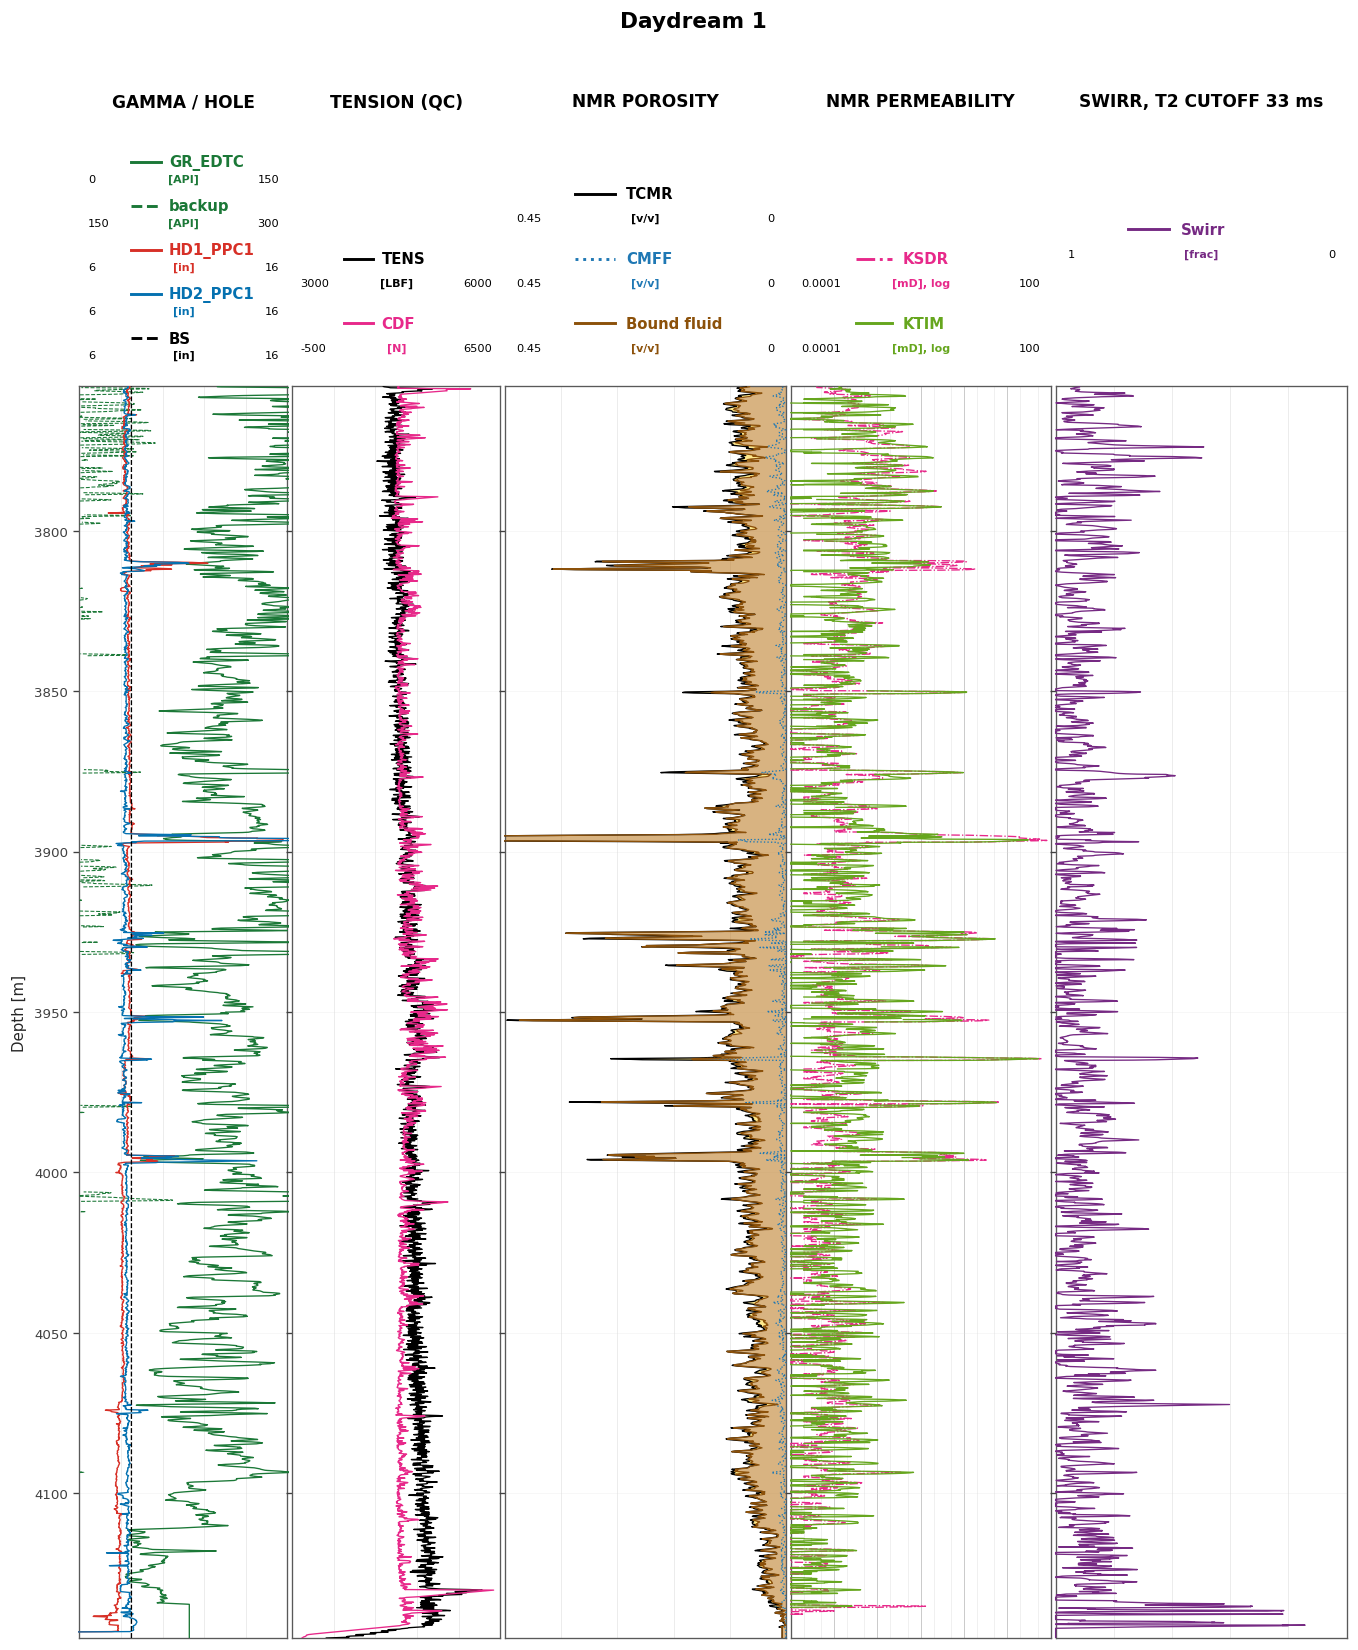

In [5]:
cmr = pp.read(pp.sample("daydream1_cmr"))
pp.nmr_panel(cmr);

The permeability track (log scale, 0.0001-100 mD) shows how tight the section
is: 85 % of `KTIM` and 89 % of `KSDR` lie below 0.01 mD, and only thin streaks, the
same depths as the porosity spikes, pass 1 mD; a few pass 10 mD (`KTIM` at most
52 mD, `KSDR` 82 mD).

### QC: the high-TCMR spikes

`TCMR` spikes above 30 pu in thin streaks. The companion curves identify
intervals requiring QC, but do not uniquely establish the cause of each spike:

- **Possible coal intervals.** Some spikes have lower GR than the section
  average. Low GR alone does not identify coal or quantify its NMR response;
  confirm lithology and the fluid/acquisition response independently.
- **Hole enlargement.** Some spike samples have caliper more than an inch
  over bit size. Borehole-fluid contamination is a possible contribution; the
  caliper flag is not a quantitative NMR correction.

Always read an NMR porosity spike against GR and caliper before calling it
reservoir. The spike samples, their median GR against the rest, and how many
of them sit in washout (HD1 more than 1 in over bit size):

In [6]:
(table.assign(spike=table["MPHI"] > 30, washout=table["HD1_PPC1"] > table["BS"] + 1)
      .groupby("spike").agg(samples=("MPHI", "size"), median_GR=("GR_EDTC", "median"), in_washout=("washout", "sum")))

,samples,median_GR,in_washout
spike,,,
False,15412,107.141,96
True,194,69.776,95


194 samples read above 30 pu (`spike` True). Their median GR is 70 API against
107 API for the rest of the section, and 95 of them, about half, sit in
washout.

## 4. Timur-Coates permeability, validated against the vendor

The Timur-Coates model needs only the summary curves:

$$k_{TC} = \left(\frac{\phi}{C}\right)^{a} \left(\frac{FFI}{BVI}\right)^{b}$$

with textbook defaults $C=10$, $a=4$, $b=2$ ($\phi$ in pu, $k$ in mD). The LAS
also carries the vendor's own Timur curve `KTIM`, reported by the vendor - a rare
chance to **validate the library against the service company** on identical
inputs.

One API gotcha first: `permeability_coates()` returns the *stored vendor
curve* when one was loaded (`prefer_stored=True` is the default). To compute
from the summary curves, pass `prefer_stored=False`.

In [7]:
kc = nmr.permeability_coates(prefer_stored=False)      # library, defaults
nmr.calibrate_coates(nmr.depth, nmr.stored_permeability["KTIM"])

NMRCalibration(model=coates, n=13171, c=9.62, a=4, b=2, R²_log=0.956, RMSE_log=0.178 dec)

`calibrate_coates` fits the constant $C$ of the model to the vendor's `KTIM`,
on the 13,171 samples where `KTIM` is positive. To see the agreement sample by
sample, we add the library curve to the well read for the panel (`pp.read`
keeps the file's deepest-first order, as `NMRData` does) and crossplot the two
on log axes.

[repository]\src\petrophys\visualization\style.py:102: DataQualityWarning: Crossplot input: 2435 of 15606 value(s) cannot be represented on the selected axes (zero-based flat indices [0, 1, 2, 3, 4]). Nonfinite and nonpositive logarithmic-axis points are omitted.
  return _label_short_log_axes(function(*args, **kwargs))


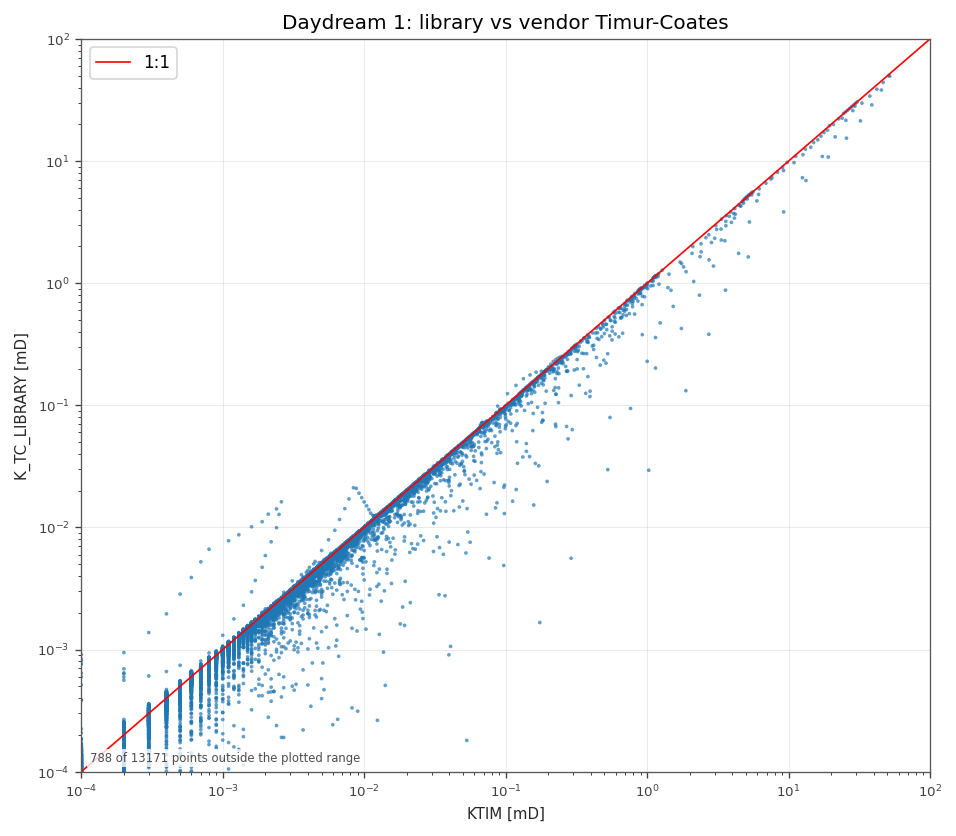

In [8]:
cmr.add_curve("K_TC_LIBRARY", kc, "mD")
cp = pp.crossplot(cmr, "KTIM", "K_TC_LIBRARY", x_log=True, y_log=True,
                  xlim=(1e-4, 1e2), ylim=(1e-4, 1e2), title="Daydream 1: library vs vendor Timur-Coates")
cp.add_line([1e-4, 1e2], [1e-4, 1e2], color="red", linewidth=1, label="1:1")
cp.show()

### Reading the validation

The fit recovers a constant $C$ = 9.62, close to the textbook default of 10,
with a log-space $R^2$ of 0.956 - the library and the vendor implement the same
model with essentially the same constants. The remaining scatter (`RMSE_log`
0.178 decades) is largest below 0.001 mD, where the LAS's four-decimal export
quantises `KTIM` (step 0.0001 mD), with some contribution from rounding of the
exported porosities.

Two honest caveats. First, this validates the **implementation**, not the
permeability: both curves come from the same empirical model on the same
inputs. Absolute accuracy still requires calibration to core
(`calibrate_coates` with real plug permeabilities, exactly as used here but
with core data). Second, `KSDR` cannot be reproduced the same way - it needs
T2lm from the bins this export does not carry - which is precisely why bin
data are worth requesting from the vendor.

### 4b. Other bundled NMR examples

The bin-based products and the core and density-neutron comparisons cannot be
shown on Daydream 1. The library bundles three separate teaching datasets
(Craig Phillips) for them. None of them belongs to Daydream 1, and none should
be joined to it or to each other:

- `pp.sample("phillips_nmr_bins")` - an eight-bin T2 example with explicit
  centres of 4-512 ms. `NMRData.bvi_from_bins` / `ffi_from_bins` split at the
  container's `t2_cutoff` (33 ms by default, `T2_CUTOFF_CLASTIC`;
  `T2_CUTOFF_CARBONATE` is 92 ms) or at a `cutoff_ms` you pass, splitting the
  bin that straddles the cutoff by its log-T2 width. The file's supplied
  summaries are a whole-bin split at 32 ms, which
  `bvi_from_bins(cutoff_ms=32.0, partial_bins=False)` and the matching
  `ffi_from_bins` call reproduce. Its source well and acquisition are not
  identified, so it demonstrates the arithmetic, not a field interpretation.
- `phillips_cmr_log` / `phillips_cmr_core` - scalar NMR curves with core
  permeability over the same interval, enough for a Timur-Coates calibration to
  core (`calibrate_coates` with plug permeabilities). They carry no T2 bins or
  T2 log-mean, so they cannot calibrate SDR.
- `phillips_gulfcoast_nmr` - conventional logs with scalar NMR from a Gulf Coast
  example (well unidentified), for comparing NMR porosity with density-neutron porosity. Mask
  -999.25 before converting the fractional MPHI/MBVI to pu, and review the
  porosity basis and hole quality first.

See the [dataset notes](https://github.com/sambalshikhar/petrophys/blob/main/src/petrophys/datasets/phillips/README.md)
for the T2 axis, mnemonics and loading examples.

## 5. Export all derived results

`NMRData.to_dataframe()` bundles the inputs, the derived curves (`MBVI`,
`SWIRR`) and every vendor and extra curve into one table for QC or hand-off.
Its `K_COATES` and `K_SDR` columns follow the same `prefer_stored=True` default
as the methods: with vendor curves loaded they repeat `KTIM` and `KSDR` (which
are also exported as `KTIM_LAS` / `KSDR_LAS`). To hand off the library's own
Timur-Coates, add it as a column, `K_TC_LIBRARY` here.
Bin-dependent columns (T2lm, pore size) are simply absent because the bins
are - the export never invents data. The first rows are the deepest samples:

In [9]:
table["K_TC_LIBRARY"] = kc
table.head()

,DEPTH,MPHI,MFFI,MBVI,T2CUTOFF,CMRP_3MS,CMR_TEMP,CDF,STIT,TENS,HD1_PPC1,HD2_PPC1,BS,GR_EDTC,KSDR,KTIM,KSDR_LAS,KTIM_LAS,K_SDR,K_COATES,SWIRR,K_TC_LIBRARY
0,4145.125,0.59,0.0,0.59,33.0,0.16,118.703,-171.989,0.004,3490.197,2.924,4.17,8.5,79.268,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,4145.100,0.59,0.0,0.59,33.0,0.16,118.703,-168.357,0.037,3530.551,2.924,4.17,8.5,79.268,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,4145.075,0.59,0.0,0.59,33.0,0.16,118.703,-164.725,0.071,3570.905,2.924,4.17,8.5,79.268,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,4145.050,0.59,0.0,0.59,33.0,0.16,118.703,-161.094,0.105,3611.260,2.924,4.17,8.5,79.268,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,4145.025,0.59,0.0,0.59,33.0,0.16,118.703,-157.462,0.139,3651.614,2.924,4.17,8.5,79.268,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


## Pitfalls & parameter choices

- **`prefer_stored=True` is the default.** With vendor curves loaded,
  `permeability_coates()` / `permeability_sdr()` return the *stored* `KTIM` /
  `KSDR`. Pass `prefer_stored=False` when you mean "compute it yourself" -
  otherwise a comparison against the vendor compares the curve to itself.
- **Porosity units.** The container works in **pu**; `from_las` converts
  fractional (v/v) CMR curves automatically. Only worry about units when
  calling the standalone `sdr_permeability` / `coates_permeability` functions.
- **SDR needs T2lm.** No bins and no `T2LM` curve means no SDR - the method
  raises instead of guessing. Request bin exports (`T2B01...`) if you need it.
- **The cutoff is data, not folklore.** Here 33 ms comes from the file's
  `T2CUTOFF` curve (the clastic default; 92 ms is a configurable carbonate starting value, requiring calibration). With only
  summary curves you also *cannot* re-split at another cutoff - `CMFF` was
  computed in the vendor's processing at 33 ms.
- **Validating against `KTIM` is not core calibration.** It checks the
  implementation and constants; absolute permeability still needs plugs.
- **QC spikes before believing them.** Low GR and caliper-over-bit flags warrant
  further lithology and borehole QC; they do not establish a unique cause.
- **This LAS is written deepest-first.** The depth index is monotonic, so it
  loads without a warning and per-sample math is safe; the first row is the
  deepest sample, so sort by depth before any step that assumes shallow-to-deep
  order.

Reference: SLB describes [T2 surface, bulk and diffusion relaxation](https://glossary.slb.com/en/terms/t/t2), [polarization-time dependence](https://glossary.slb.com/en/terms/p/polarization_time), and [adjustable cutoff processing](https://www.slb.com/products-and-services/delivering-digital-at-scale/software/techlog-wellbore-software/techlog/techlog-petrophysics/techlog-nuclear-magnetic-resonance).


## Recap

- A real CMR summary deliverable (Daydream 1) loads in one call:
  `NMRData.from_las(path)` -
  aliases, pu conversion, `MBVI = MPHI - MFFI`, cutoff, and vendor curves all
  handled.
- The porosity partition says **tight coal measures**: low total NMR porosity,
  very little free fluid and a high median Swirr; TCMR spikes need independent lithology and
  borehole QC before they can inform a pay interpretation.
- Library **Timur-Coates matches the vendor's KTIM** closely, and
  `calibrate_coates` recovers a constant $C$ close to the textbook 10.
- **T2-bin products (T2 distribution, T2lm, SDR, pore size) need bin data**,
  which this summary export does not carry; the API refuses cleanly when they
  are absent, and the vendor's delivered `KSDR` shows what those bins would buy.

## Try it yourself

> **Exercise 1.** Load the shallow section
> (`pp.sample("daydream1_cmr_shallow")`, about 2840-3050 m) the same way and
> compare its Swirr and `KTIM` distributions against the deep section. Which
> section has more free fluid?
>
> **Exercise 2.** Re-run `calibrate_coates` with `fit_exponents=True`. Do the
> exponents move away from $(a, b) = (4, 2)$, and what does that say about the
> parameterisation the vendor used?
>
> **Exercise 3.** `TCMR - CMRP_3MS` isolates the porosity relaxing faster than
> 3 ms (micro/clay-bound signal). `nmr.mphi` holds TCMR converted to pu;
> `CMRP_3MS` is in `nmr.extra_curves`. Check its values against its `V/V`
> label before subtracting - do they look like fractions or porosity units?
> Then plot the difference against `GR_EDTC`: does micro-porosity track
> shaliness?

## What's next

Continue with **15 - Capillary Pressure & Saturation-Height**, where the
bound/free-fluid ideas from NMR reappear as capillary equilibrium above the
free-water level, and we predict water saturation from porosity, permeability
and height.